# Toward a full SPH implementation in Peano


## Particle behaviour

As usual, in peano 4 the particle-particle interactions are handled in terms of the active and local particle sets. Notice that in this we now do not simply rely on the particles of the adjacent vertices of a cell -- see the sketch below. To understand what the individual particles in the sketch are supposed to mean and how they are maintained and exposed to the user, please consult the documentation of the ParticleParticleInteraction class in the Python toolbox directory. It contains a lot explanations.

**Remarks**:
- For particle-particle interactions: bear in mind that the local set is a subset of the active set, so be careful about any unwanted self-interactions.
- In this scheme, the following relation should be satisfied:

\begin{align}
H_{\rm SPH} \leq R^{\rm peano}_{\rm cutoff} \leq \frac{\Delta x}{2}\,,
\end{align}

where $H_{\rm SPH}$($\equiv\gamma_K h$) is the SPH interaction radius, $R^{\rm peano}_{\rm cutoff}$ is the internal cut-off radius and $\Delta x$ the cell size.

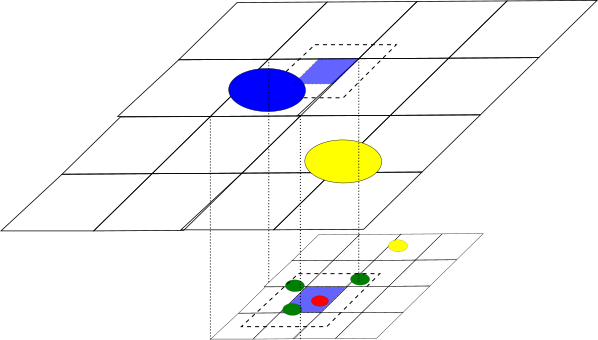

In [1]:
from IPython.display import Image
Image("../../../python/peano4/toolbox/particles/dependency_sets.png")

In [2]:
import os

import peano4
import peano4.dastgen2
import peano4.toolbox
import peano4.toolbox.particles
import dastgen2

DaStGen 2 (C) www.peano-framework.org
Peano 4 (C) www.peano-framework.org


In [3]:
# If we want to start a project from scratch, we may want to remove some of the generated code
!make clean; rm -r actions/ vertexdata/ repositories/ globaldata/ celldata/ observers/ 

project = peano4.Project( ["examples", "particles"], "sph-peano", "." )

rm -f celldata/ParticleSetCellStatistics.o vertexdata/ParticleSet.o globaldata/Particle.o repositories/DataRepository.o ./observers/CreateGrid2peano4_toolbox_CreateRegularGrid0.o ./observers/CreateGrid.o ./observers/Init2peano4_toolbox_particles_UpdateParticleGridAssociation0.o ./observers/Init2peano4_toolbox_particles_InsertRandomParticlesIntoUnrefinedCells1.o ./observers/Init2peano4_toolbox_particles_ParticleTreeAnalysis2.o ./observers/Init.o ./actions/DensityNonSym.o ./observers/DensityNonSym2peano4_toolbox_particles_UpdateParticleGridAssociation1.o ./observers/DensityNonSym2peano4_toolbox_particles_ParticleParticleInteraction2.o ./observers/DensityNonSym2peano4_toolbox_particles_ParticleAMR3.o ./observers/DensityNonSym2peano4_toolbox_particles_ParticleTreeAnalysis4.o ./observers/DensityNonSym.o ./actions/HydroPrepareGradient.o ./observers/HydroPrepareGradient2peano4_toolbox_particles_UpdateParticleGridAssociation1.o ./observers/HydroPrepareGradient2peano4_toolbox_particles_Particle

## Prepare code

Peano's API does not know which settings to use on the present system. To make it copy/clone the settings identified by ./configure, we ask it to parse the generated configuration scripts. 

In [4]:
build_mode = peano4.output.CompileMode.Asserts
#build_mode = peano4.output.CompileMode.Release
project.output.makefile.parse_configure_script_outcome( "../../.." )
project.output.makefile.set_mode( build_mode )

parse configure outcome ../../../config.log to extract configure settings
found the configure call info   $ ./configure --with-mpi=mpicxx --with-multithreading=omp CXXFLAGS=--std=c++17 -DnoMPISupportsSingleSidedCommunication -fopenmp -funroll-loops CC=gcc CXX=g++ FC=gfortran --enable-loadbalancing --enable-exahype --enable-particles --enable-blockstructured --no-create --no-recursion

parse configure outcome ../../../src/Makefile to extract compile settings
add CXX=mpicxx
add CXXFLAGS=--std=c++17 -DnoMPISupportsSingleSidedCommunication -fopenmp -funroll-loops
add CXXFLAGS_PEANO_2D_ASSERTS=-DDimensions=2 -DPeanoDebug=2 -g3 -O0
add CXXFLAGS_PEANO_2D_DEBUG=-DDimensions=2 -DPeanoDebug=4 -g3 -O0
add CXXFLAGS_PEANO_2D_RELEASE=-DDimensions=2 -DPeanoDebug=0
add CXXFLAGS_PEANO_2D_STATS=-DDimensions=2 -DPeanoDebug=0 -DTrackStatistics
add CXXFLAGS_PEANO_2D_TRACE=-DDimensions=2 -DPeanoDebug=1 -g3
add CXXFLAGS_PEANO_3D_ASSERTS=-DDimensions=3 -DPeanoDebug=2 -g3 -O0
add CXXFLAGS_PEANO_3D_DEBUG=-DDime

## Model the particle

We create the particle through the toolbox. A particle by definition has a position, so we just need to add everything else for SPH:

- Velocity array (${\bf v}$)
- Acceleration array (${\bf a}\equiv{\rm d}{\bf v}/{\rm d}t$)
- Mass
- Kernel smoothing length ($h$)
- Density
- Pressure
- Internal Energy ($u$)
- Time derivative of internal energy (${\rm d}u/{\rm d}t$)
- Variable-smoothing length (AKA "grad-h") term ($\Omega$).
    - In practice, we store $\Omega-1$ during the loops, and "1" when these are finished.

TO ADD:
- Time derivative of smoothing length (${\rm d}h/{\rm d}t$)




We add a marker to indicate the next calculation step required for a particle so we don't perform the same step on a particle twice in a row.

We also add an array to store the new position of a particle after a timestep is completed. We will use this to move the particle at the start of the subsequent timestep.

In [5]:
particle = peano4.toolbox.particles.Particle("Particle")

# Define properties
v_attr    = peano4.dastgen2.Peano4DoubleArray("v","Dimensions")
a_attr    = peano4.dastgen2.Peano4DoubleArray("a","Dimensions")
mass_attr    = dastgen2.attributes.Double("mass")
smoothL_attr = dastgen2.attributes.Double("smoothingLength")
density_attr = dastgen2.attributes.Double("density")
pressure_attr= dastgen2.attributes.Double("pressure")
u_attr       = dastgen2.attributes.Double("u")
uDot_attr    = dastgen2.attributes.Double("uDot")
rhoDot_attr  = dastgen2.attributes.Double("rhoDot")
soundSpeed_attr = dastgen2.attributes.Double("soundSpeed")
wcount_attr   = dastgen2.attributes.Double("wcount")
wcount_dh_attr= dastgen2.attributes.Double("wcount_dh")
Ncount_attr   = dastgen2.attributes.Integer("Ncount")

# For variable smoothing length
Omega_attr = dastgen2.attributes.Double("Omega")
rho_dh_attr= dastgen2.attributes.Double("rho_dh")
hDot_attr  = dastgen2.attributes.Double("hDot")

# Artificial viscosity
rot_v_attr = peano4.dastgen2.Peano4DoubleArray("rot_v","Dimensions")
div_v_attr    = dastgen2.attributes.Double("div_v")
alpha_AV_attr = dastgen2.attributes.Double("alpha_AV")
v_sig_AV_attr = dastgen2.attributes.Double("v_sig_AV")
alpha_AV_max_ngb_attr = dastgen2.attributes.Double("alpha_AV_max_ngb")
balsara_attr  = dastgen2.attributes.Double("balsara")

# Thermal diffusion
laplace_u_attr = dastgen2.attributes.Double("laplace_u")


# Needed?
has_been_kicked_attr = dastgen2.attributes.Boolean("hasBeenKicked")
has_converged_attr= dastgen2.attributes.Boolean("hasConverged")
smoothL_prev_attr = dastgen2.attributes.Double("smoothingLengthPrevious")

# Debug
DebugNeg_attr     = dastgen2.attributes.Double("DebugNeg")

# Add particle properties
particle.data.add_attribute(v_attr)
particle.data.add_attribute(a_attr)
particle.data.add_attribute(mass_attr)
particle.data.add_attribute(density_attr)
particle.data.add_attribute(pressure_attr)
particle.data.add_attribute(u_attr)
particle.data.add_attribute(uDot_attr)
particle.data.add_attribute(smoothL_attr)
particle.data.add_attribute(rhoDot_attr)
particle.data.add_attribute(Ncount_attr)
particle.data.add_attribute(wcount_attr)
particle.data.add_attribute(wcount_dh_attr)
particle.data.add_attribute(soundSpeed_attr)

# For variable smoothing length
particle.data.add_attribute(Omega_attr)
particle.data.add_attribute(rho_dh_attr)
particle.data.add_attribute(hDot_attr)

# Artificial viscosity
particle.data.add_attribute(div_v_attr)
particle.data.add_attribute(rot_v_attr)
particle.data.add_attribute(alpha_AV_attr)
particle.data.add_attribute(v_sig_AV_attr)
particle.data.add_attribute(alpha_AV_max_ngb_attr)
particle.data.add_attribute(balsara_attr)

# Thermal difussion
particle.data.add_attribute(laplace_u_attr)


# Needed?
particle.data.add_attribute(has_been_kicked_attr)
particle.data.add_attribute(has_converged_attr)
particle.data.add_attribute(smoothL_prev_attr)

# Debug
particle.data.add_attribute(DebugNeg_attr)

particles = peano4.toolbox.particles.ParticleSet(particle)

This particle has to be added to the project. This way the project knows that we are working with this guy. We associate the particle with the vertices, as we work with the pidt (particle in dual tree) algorithm. 

In [6]:
project.datamodel.add_global_object(particle)
project.datamodel.add_vertex       (particles)

## Export global SPH constants

There are plenty of constant simulation paramaters to specify for our SPH simulation - we do that here. 

In [7]:
Dimensions = 2
project.output.makefile.set_dimension(Dimensions)

In [8]:
from numpy import pi

GLOBAL_TIME_STEP_SIZE = "1e-3"

# SPH parameters
GAMMA = str(5/3)
KERNEL_SUPPORT_RAD = "2"  # Cubic Spline = 2. Can be different in other kernels.
CFL_CONSTANT = "0.2"

# Artificial viscosity parameters
ALPHA_AV= "1"
ALPHA_MAX_AV= "1"
BETA_AV = "2"
ALPHA_U = "1" # Internal Energy

if(Dimensions==2):
    N_ngbs_mean = 10.0  # Free parameter to estimate h based on how many average ngbs we want to use
    SMOOTH_L_FAC = str( (1.   /pi*N_ngbs_mean)**(1./2.)/float(KERNEL_SUPPORT_RAD) ) 
    CUBIC_SPLINE_SIGMA = str(10/(7*pi))
    
elif(Dimensions==3):
    N_ngbs_mean = 57.9
    SMOOTH_L_FAC = str( (3./4./pi*N_ngbs_mean)**(1./3.)/float(KERNEL_SUPPORT_RAD) ) 
    CUBIC_SPLINE_SIGMA = str(1/pi)

print(SMOOTH_L_FAC, CUBIC_SPLINE_SIGMA)

# parameters specific to a given problem (e.g., Sedov blast, Sod wave, ...)
ENERGY_SPIKE = "1.0"
BLAST_CENTER = "0.5"    # {0.5,0.5}
BLAST_ENERGY = "0.2"
SPIKE_RADIUS = "0.035"

project.constants.export_const_with_type("GLOBAL_TIME_STEP_SIZE", GLOBAL_TIME_STEP_SIZE, "double")
project.constants.export_const_with_type("KERNEL_SUPPORT_RAD", KERNEL_SUPPORT_RAD, "double")
project.constants.export_const_with_type("SMOOTH_L_FAC"      , SMOOTH_L_FAC      , "double")
project.constants.export_const_with_type("CUBIC_SPLINE_SIGMA", CUBIC_SPLINE_SIGMA, "double")
project.constants.export_const_with_type("ENERGY_SPIKE", ENERGY_SPIKE, "double")
project.constants.export_const_with_type("BLAST_CENTER", BLAST_CENTER, "double")
project.constants.export_const_with_type("BLAST_ENERGY", BLAST_ENERGY, "double")
project.constants.export_const_with_type("SPIKE_RADIUS", SPIKE_RADIUS, "double")
project.constants.export_const_with_type("CFL_CONSTANT", CFL_CONSTANT, "double")
project.constants.export_const_with_type("GAMMA"   , GAMMA   , "double")
project.constants.export_const_with_type("ALPHA_AV", ALPHA_AV, "double")
project.constants.export_const_with_type("BETA_AV" , BETA_AV , "double")
project.constants.export_const_with_type("ALPHA_U" , ALPHA_U , "double")

0.8920620580763856 0.4547284088339867


## Model the setup phases

The setup remains almost unchanged. I give all particles a biased random initial velocity. This will introduce an adaptive mesh, as particles will cluster in the bottom left part of the 2d domain.

In [9]:
mesh_size = 0.4

particle_tree_analysis = peano4.toolbox.particles.ParticleTreeAnalysis(particles)
project.datamodel.add_cell(particle_tree_analysis.cell_marker)   # read docu of ParticleTreeAnalysis

create_grid = peano4.solversteps.Step( name="CreateGrid", add_user_defined_actions=False )
create_grid.add_action_set( peano4.toolbox.CreateRegularGrid(mesh_size) )
create_grid.use_vertex(particles)
create_grid.use_cell(particle_tree_analysis.cell_marker)
project.solversteps.add_step(create_grid)

## Initial conditions for particles

In [10]:
initialisation_snippet = """
 
 particle->setCutOffRadius(0.15);

 // We will set random velocities for (v_x, v_y)
 particle->setV( 0, 0e0*(0.5 -((double) rand() / (RAND_MAX))) );
 particle->setV( 1, 0e0*(0.5 -((double) rand() / (RAND_MAX))) );

 // For SPH, we also want to initialise a few more properties:
 particle->setMass    (1E-1);       
 particle->setDensity ( particle->getMass()/( M_PI*std::pow(0.2/10/2,2) ) );        
 particle->setU       (1E-2);
 particle->setPressure( (GAMMA - 1)*particle->getDensity()*particle->getU() );
 particle->setSmoothingLength( SMOOTH_L_FAC * std::pow(particle->getMass()/particle->getDensity(), 1.0/Dimensions) );
 particle->setSoundSpeed( std::pow(GAMMA*(GAMMA -1)*particle->getU(), 0.5 ) );
 
 particle->setSmoothingLengthPrevious(1E-1);
 particle->setHasBeenKicked(false);

 // Initialize the remaining fields to zero
 particle->setA( 0, 0 );
 particle->setA( 1, 0 );
 particle->setUDot  (0.0);        
 particle->setHDot  (0.0);        
 particle->setWcount(0.0);        
 particle->setNcount(0  );        
 particle->setOmega (0.0);        
 particle->setRhoDot(0.0);        
 particle->setRho_dh(0.0);           
 particle->setWcount_dh(0.0);           
 particle->setLaplace_u(0.0);
 particle->setDebugNeg(-1.0);


"""

init_setup = peano4.solversteps.Step( name="Init", add_user_defined_actions=False )
init_setup.use_vertex(particles)
init_setup.use_cell(particle_tree_analysis.cell_marker)
init_setup.add_action_set( peano4.toolbox.particles.UpdateParticleGridAssociation(particles) )
init_setup.add_action_set( peano4.toolbox.particles.InsertRandomParticlesIntoUnrefinedCells(
  particle_set=particles,
  average_distance_between_particles=mesh_size/10,
  initialisation_call=initialisation_snippet,
  noise=True,
  additional_includes=""" 
    #include "Constants.h" 
    """ ))
init_setup.add_action_set( particle_tree_analysis )
project.solversteps.add_step(init_setup)

# Model the steps of the simulation

In the following, we model each step that will be invoked by main.cpp to run the simulation. The generated C++ code based on these will be outputted into `/observers/`

## Density loop with variable smoothing length

In the case of variable smoothing length, $h\neq{\rm const.}$, we need to calculate this alongside with density in a self-consistent way. We proceed in two steps as follows:

1. We loop over neighbours ($b$) with the current value of $h$, to calculate the various sums:

\begin{align}
\rho_a& = \sum_b m_b W(|{\bf r}_a - {\bf r}_b|, h_a)\\
\delta\Omega_a\equiv\Omega_a -1 &= - \frac{\partial h_a}{\partial \rho_a}\sum_b m_b\frac{\partial W_{ab}(h_a)}{\partial h_a} \qquad\qquad (\delta\Omega_a=0 \quad \textrm{for constant $h$})\\
\frac{{\rm d}{\rho_a}}{{\rm d}t} &= \frac{1}{\Omega_a}\sum_b m_b{v}_{ab}\cdot{\bf \nabla}_aW_{ab}(h_a)
\end{align}
The latter is later used to calculate the initial guess for the Newton-Raphson, which can reduce the number of required iterations.

In [11]:
calc_densities_var_h = peano4.solversteps.Step( "DensityNonSym" )
calc_densities_var_h.use_vertex(particles)
calc_densities_var_h.use_cell(particle_tree_analysis.cell_marker)
calc_densities_var_h.add_action_set( peano4.toolbox.particles.UpdateParticleGridAssociation(particles) )

particle_particle_compute_kernel = """

 /*
  * Non-symmetric density calculation (as per Swift terminology). 
  * In this, only the Local particle is updated (in the symmetric case, both are updated at the same time).
  *
  *
  * Here we calculate the density, Omega and drho/dt sums.
  * The latter can be used in the Newton-Raphson iteration.
  *
  * Subscripts a and b represent indices of Local and Active particles, respectively:
  *
  * h_a: Smoothing length of Local particle
  * h_b: Smoothing length of Active particle
  * r  : Distance between the two particles
  * dx : Vector separating the two particles (x_loc - x_act)
  *
  */


  tarch::la::Vector<Dimensions,double> dx = localParticle->getX() - activeParticle->getX();
  const double r = tarch::la::norm2(dx);
  tarch::la::Vector<Dimensions,double> dx_unit = dx/r;

  // Velocity terms for viscosity
  tarch::la::Vector<Dimensions,double> dv_ab;
  tarch::la::Vector<Dimensions,double> curlvr(0.0);

  // Retrieve basic properties of local and active particles
  const double rho_b = activeParticle->getDensity();

  const double m_a = localParticle ->getMass();  
  const double m_b = activeParticle->getMass();  

  const double h_a = localParticle->getSmoothingLength();

  // Normalized distance to evaluate kernel
  const double q_a = r / h_a;
  
  // Get actual interaction radius
  const double cutoffR = KERNEL_SUPPORT_RAD*h_a;
  
  if ( tarch::la::smaller( r,cutoffR ) ) {
    if ( tarch::la::greater( r,0.0 ) ) {
     
      // Evaluate kernel and its derivative
      double w_a, dw_a_dq;
      kernel_deval(q_a, w_a, dw_a_dq);

      // Normalization factors 
      double W_a, dW_a_dh;
      W_a = w_a / std::pow( h_a, Dimensions );
      dW_a_dh = - ( Dimensions*w_a + q_a*dw_a_dq ) / std::pow( h_a, Dimensions +1 );

      // Increment density of Local particle
      localParticle->setDensity( localParticle-> getDensity() + m_b * W_a ); 

      // Increment number density as well
      localParticle->setWcount ( localParticle-> getWcount () +       W_a );
      
      // Increment "Exact" number density (for debugging)
      localParticle->setNcount ( localParticle-> getNcount () + 1 ); 

      // Increment drho/dh
      localParticle->setRho_dh   ( localParticle->getRho_dh()    + m_b*dW_a_dh ); 

      // Increment Omega of Local particle
      localParticle->setOmega    ( localParticle->getOmega()     + m_b*dW_a_dh );

      // Increment dWcount/dh
      localParticle->setWcount_dh( localParticle->getWcount_dh() +     dW_a_dh ); 

      assertion3( not std::isnan( localParticle->getOmega() ), localParticle->toString(), localParticle->getOmega(), dW_a_dh );
      
      /* Calculation of drho/dt.
       * Not used in Swift?
       * Can be used to predict smoothing length for initial guess of N-R iterations.
       */
      
      // Evaluate for h_a (local particle), i.e.  Grad_a{W_ab(h_a)}

      double delW_a = dw_a_dq / std::pow( h_a, Dimensions + 1 );

      tarch::la::Vector<Dimensions,double> dW_a_dr = delW_a*dx_unit;
      
      // Compute dot product of velocity difference vector and Grad_a{W}
      dv_ab = localParticle->getV() - activeParticle->getV();

      const double dv_ab_dot_Grad_W = tarch::la::dot( dv_ab , dW_a_dr );

      // Increment drho/dt of Local particle
      localParticle->setRhoDot( localParticle-> getRhoDot() + m_b *dv_ab_dot_Grad_W );
           
      /* Now we need to compute the div terms */
          
      const double r_inv = r ? 1.0 / r : 0.0;     
      const double fac_a = m_a * dw_a_dq * r_inv;

      /* Compute dv dot r */
      const double dvdr = tarch::la::dot( dv_ab , dx );
      localParticle->setDiv_v( localParticle->getDiv_v() - fac_a * dvdr );
      
      /* Compute dv cross r */
      /* Notice this term only makes sense in 3D */
//      curlvr = tarch::la::cross( dv_ab, dx );
//      localParticle->setRot_v( localParticle->getRot_v() + fac_a * curlvr );


    } 
  }
    
"""

touch_particle_last_time_compute_kernel = """

  /* Here we finalize the calculations from the density loop */

  if(localParticle->getParallelState()==globaldata::Particle::ParallelState::Local){

    /* Retrieve some properties */
    const double m_a = localParticle->getMass();
    const double h_a = localParticle->getSmoothingLength();
    
    const double h_inv_dim = 1.0/std::pow( h_a, Dimensions );
    const double h_inv_dim_plus_one = h_inv_dim/h_a;

    // Default SPH kernel (cubic spline)
    double W_a = CUBIC_SPLINE_SIGMA ; // kernel form taken at q=0
      
    /* Add the contributions due to the particle itself (i.e. at q=0) */

    localParticle->setDensity  ( localParticle->getDensity()   + m_a * W_a * h_inv_dim );                      
    localParticle->setWcount   ( localParticle->getWcount()    +       W_a * h_inv_dim );                      
    localParticle->setOmega    ( localParticle->getOmega()     + m_a * (-Dimensions * W_a * h_inv_dim_plus_one) );   
    localParticle->setRho_dh   ( localParticle->getRho_dh()    + m_a * (-Dimensions * W_a * h_inv_dim_plus_one) );   
    localParticle->setWcount_dh( localParticle->getWcount_dh() +       (-Dimensions * W_a * h_inv_dim_plus_one) );

    const double rho_inv = 1.0 / localParticle->getDensity();

    /* Finish calculation of the velocity curl components */
    localParticle->setRot_v( localParticle->getRot_v() * h_inv_dim_plus_one * rho_inv);

    /* Finish calculation of the velocity divergence */
    localParticle->setDiv_v( localParticle->getDiv_v() * h_inv_dim_plus_one * rho_inv);
  
  }
  
  
"""

touch_particle_first_time_compute_kernel = """

  if(localParticle->getParallelState()==globaldata::Particle::ParallelState::Local){

    // we'll accumulate the data throughout mesh/particle traversal
    localParticle->setDensity (0.0);                      
    localParticle->setWcount  (0.0);                      
    localParticle->setOmega   (0.0);   
    localParticle->setRho_dh  (0.0);   
    localParticle->setWcount_dh(0.0);   
    localParticle->setRhoDot  (0.0);   
    localParticle->setPressure(0.0);  
    localParticle->setDiv_v   (0.0);   
    localParticle->setRot_v   (0.0);   
    localParticle->setNcount  (0);
    
  } 
    

"""

calc_densities_var_h.add_action_set( peano4.toolbox.particles.ParticleParticleInteraction(
  particle_set=particles,
  particle_particle_interaction_kernel=particle_particle_compute_kernel,
  touch_vertex_first_time_compute_particle_update_kernel=touch_particle_first_time_compute_kernel,
  touch_vertex_last_time_compute_particle_update_kernel=touch_particle_last_time_compute_kernel,
  additional_includes="""
#include "Constants.h"
#include "kernel_hydro.h"
  """
))
calc_densities_var_h.add_action_set( peano4.toolbox.particles.ParticleAMR(particles,particle_tree_analysis,min_particles_per_cell=10) )
calc_densities_var_h.add_action_set( particle_tree_analysis )
project.solversteps.add_step(calc_densities_var_h)

## Prepare Gradients

It calculates a number of quantities involving gradients, such as $\Omega$ ("grad-h" terms)

Non-loop operation, "ghost task".

In [12]:
prepare_gradient = peano4.solversteps.Step( "HydroPrepareGradient" )
prepare_gradient.use_vertex(particles)
prepare_gradient.use_cell(particle_tree_analysis.cell_marker)
prepare_gradient.add_action_set( peano4.toolbox.particles.UpdateParticleGridAssociation(particles) )

particle_particle_compute_kernel = """

  /* We do not excecute any specific action here */
    
"""

touch_particle_last_time_compute_kernel = """

  if(localParticle->getParallelState()==globaldata::Particle::ParallelState::Local){

    // Retrieve basic properties of local and active particles
    const double rho_a = localParticle->getDensity();
    const double m_a = localParticle->getMass();  
    const double h_a = localParticle->getSmoothingLength();
  
    /* Compute the norm of the curl */
    const double curl_v = tarch::la::norm2( localParticle->getRot_v() );
  
    /* Compute the norm of div v */
    const double abs_div_v = tarch::la::abs( localParticle->getDiv_v() );
    
    /* Compute the sound speed */
    const double soundspeed =  std::pow( localParticle->getU() * GAMMA * (GAMMA -1), 0.5 );
  
    /* Compute the Balsara Switch */
    const double balsara = abs_div_v / (abs_div_v + curl_v + 0.0001 * soundspeed / h_a);
    
    // Construct final expression of Omega
    
    /* Swift Expression for equivalent to Omega term ("f", see also Springel and Hernquist) */
   
    const double common_factor = h_a/rho_a/Dimensions;
    double grad_h_term;
    const double grad_W_term = common_factor * localParticle->getWcount_dh();
    
    // Avoid problematic particles
    if(grad_W_term < -0.9999){
         /* if we get here, we either had very small neighbour contributions
           (which should be treated as a no neighbour case in the ghost) or
           a very weird particle distribution (e.g. particles sitting on
           top of each other). Either way, we cannot use the normal
           expression, since that would lead to overflow or excessive round
           off and cause excessively high accelerations in the force loop */
      grad_h_term = 0;
    } else {
      grad_h_term = common_factor * localParticle->getRho_dh()/(1 + grad_W_term);
    }
  
    /* Update Omega.
       Notice that this is equivalent to the inverse of the f_ij = 1 - f_i/_m_j term used in Swift */
       
  //  localParticle->setOmega( 1.0/(1.0 - grad_h_term/m_a ) );   
  
    /* Update variables */
    const double P_a = rho_a * localParticle->getU() * (GAMMA - 1);
    localParticle->setPressure( (P_a < 0) ? 0 : P_a );
    localParticle->setSoundSpeed(soundspeed);
    localParticle->setBalsara (balsara);
  
    /* Notice this is equivalent to "1/f" from Springel & Hernquist  */
    localParticle->setOmega( 1.0 + common_factor*localParticle->getRho_dh() );
  
    // Reset ill cases where Omega is too small and yields extremely large accelerations.
    if(localParticle->getOmega() <= 1e-2){
      localParticle->setOmega(1.0);
    }
    
    // Reset ill case (problematic boundary particles?)
      if( std::isfinite(localParticle->getOmega()) ){
      localParticle->setOmega(1.0);
    }
    
    /* Old expression for Omega and safety checks
    
    const double dh_drho_a = - h_a/rho_a/Dimensions;
    localParticle->setOmega ( 1.0 - dh_drho_a * localParticle->getOmega() );  // Final value of Omega
                                                                                                    
    // Correct the value of Omega if gone ill
    if(localParticle->getOmega() <= 0){
      localParticle->setOmega(1.0);
    }
  
    // DEBUGGING ill cases where Omega is too small and yields extremely large accelerations.
    if(localParticle->getOmega() <= 1e-2){
      localParticle->setOmega(1.0);
    }
  
    */
  
  }

"""

touch_particle_first_time_compute_kernel = """

   /* We do not excecute any specific action here */
   
   // DEBUG
   assertion3( not localParticle->getDensity()==0, localParticle->toString(), localParticle->getDensity(), localParticle->getOmega() );  

   
"""

prepare_gradient.add_action_set( peano4.toolbox.particles.ParticleParticleInteraction(
  particle_set=particles,
  particle_particle_interaction_kernel=particle_particle_compute_kernel,
  touch_vertex_first_time_compute_particle_update_kernel=touch_particle_first_time_compute_kernel,
  touch_vertex_last_time_compute_particle_update_kernel=touch_particle_last_time_compute_kernel,
  additional_includes="""
#include "Constants.h" 
  """
))
prepare_gradient.add_action_set( peano4.toolbox.particles.ParticleAMR(particles,particle_tree_analysis,min_particles_per_cell=10) )
prepare_gradient.add_action_set( particle_tree_analysis )
project.solversteps.add_step(prepare_gradient)

##  Gradient loop

In [13]:
gradient_non_sym = peano4.solversteps.Step( "GradientNonSym" )
gradient_non_sym.use_vertex(particles)
gradient_non_sym.use_cell(particle_tree_analysis.cell_marker)
gradient_non_sym.add_action_set( peano4.toolbox.particles.UpdateParticleGridAssociation(particles) )

particle_particle_compute_kernel = """

 /*
  * Non-symmetric gradient calculation (as per Swift terminology). 
  * In this, only the Local particle is updated (in the symmetric case, both are updated at the same time).
  *
  * Subscripts a and b represent indices of Local and Active particles, respectively:
  *
  * h_a: Smoothing length of Local particle
  * h_b: Smoothing length of Active particle
  * r  : Distance between the two particles
  * dx : Vector separating the two particles (x_loc - x_act)
  *
  */
  
  tarch::la::Vector<Dimensions,double> dx = localParticle->getX() - activeParticle->getX();
  const double r = tarch::la::norm2(dx);
  const double r_inv = r ? 1.0 / r : 0.0;

  // Velocity terms for viscosity
  tarch::la::Vector<Dimensions,double> dv_ab;
  tarch::la::Vector<Dimensions,double> curlvr(0.0);

  // Retrieve basic properties of local and active particles
  const double rho_b = activeParticle->getDensity();

  const double m_a = localParticle ->getMass();  
  const double m_b = activeParticle->getMass();  

  const double h_a = localParticle->getSmoothingLength();

  // Normalized distance to evaluate kernel
  const double q_a = r / h_a;
  
  // Get actual interaction radius
  const double cutoffR = KERNEL_SUPPORT_RAD*h_a;
  
  if ( tarch::la::smaller( r,cutoffR ) ) {
    if ( tarch::la::greater( r,0.0 ) ) {     
      
      /* We need to construct the maximal signal velocity between our particle
       * and all of it's neighbours */

      const double c_a = localParticle ->getSoundSpeed();
      const double c_b = activeParticle->getSoundSpeed();
        
      /* Compute dv dot r */
      const double dvdr = tarch::la::dot( dv_ab , dx );
      
      /* Are the particles moving towards each others ? */
      const double omega_ab = std::min(dvdr, 0.0);
      const double mu_ab = r_inv * omega_ab; /* This is 0 or negative */
    
      /* Signal velocity */
      const double new_v_sig = c_a + c_b - BETA_AV * mu_ab;
    
      /* Update if we need to */
      localParticle->setV_sig_AV( std::max( localParticle->getV_sig_AV(), new_v_sig ) );
    
      /* Calculate Del^2 u for the thermal diffusion coefficient. */
      /* Need to get some kernel values F_ij = wi_dx */
      
      double w_a, dw_a_dq;
      kernel_deval(q_a, w_a, dw_a_dq);
    
      const double delta_u_factor = ( localParticle->getU() - activeParticle->getU() ) * r_inv;
      
      localParticle->setLaplace_u( localParticle->getLaplace_u() + m_b * delta_u_factor * dw_a_dq / rho_b);
    
      /* Set the maximal alpha from the previous step over the neighbours
       * (this is used to limit the diffusion in hydro_prepare_force) */
      
      const double alpha_b = activeParticle->getAlpha_AV();
      localParticle->setAlpha_AV_max_ngb( std::max(localParticle->getAlpha_AV_max_ngb(), alpha_b) );

    }
  }
   
"""

touch_particle_last_time_compute_kernel = """

   /* Finalize gradient calculation */
   
   /* Here we do the equivalent to "hydro_end_gradient" in Swift. */
   
   if(localParticle->getParallelState()==globaldata::Particle::ParallelState::Local){

     const double h_a = localParticle->getSmoothingLength();
     const double h_inv_dim = 1.0/std::pow( h_a, Dimensions );
     const double h_inv_dim_plus_one = h_inv_dim/h_a;
   
     /* Include the extra factors in the del^2 u */
   
     localParticle->setLaplace_u( localParticle->getLaplace_u() * 2.0 * h_inv_dim_plus_one );
   
   }

"""

touch_particle_first_time_compute_kernel = """
 
  /* Here we do the equivalent to "hydro_reset_gradient" in Swift,
   * which is a function called after "hydro_prepare_gradient".
   * This function prepares the particles for the gradient loop. */
   
   if(localParticle->getParallelState()==globaldata::Particle::ParallelState::Local){
    
     localParticle->setV_sig_AV( 2.0 * localParticle->getSoundSpeed() );
     localParticle->setAlpha_AV_max_ngb( localParticle->getAlpha_AV() );
   
   }

"""

gradient_non_sym.add_action_set( peano4.toolbox.particles.ParticleParticleInteraction(
  particle_set=particles,
  particle_particle_interaction_kernel=particle_particle_compute_kernel,
  touch_vertex_first_time_compute_particle_update_kernel=touch_particle_first_time_compute_kernel,
  touch_vertex_last_time_compute_particle_update_kernel=touch_particle_last_time_compute_kernel,
  additional_includes="""
#include "Constants.h"
#include "kernel_hydro.h"
#include <cmath>
  """
))
gradient_non_sym.add_action_set( peano4.toolbox.particles.ParticleAMR(particles,particle_tree_analysis,min_particles_per_cell=10) )
gradient_non_sym.add_action_set( particle_tree_analysis )
project.solversteps.add_step(gradient_non_sym)

## Newton-Raphson iterations to calculate $h$

2. Once the above have been calculated, we solve iteratively for $h$ using Newton-Raphson:

\begin{align}
\zeta(h_a)&\equiv m_a\left(\frac{\eta}{h_a}\right)^{3}-\sum_b m_b W_{ab}(h_a)=0\\
\textrm{Initial guess:} &\qquad\qquad h^{\rm ini}_a =h_a + \Delta t \frac{\partial h_a}{\partial\rho_a}\frac{d\rho_a}{dt}\\ 
\textrm{N-R iteration:}&\qquad\qquad h_{a,{\rm new}}=h_a - \frac{\zeta({h_a})}{\zeta'(h_a)} \qquad \textrm{where:}\qquad \zeta'(h_a)=-\frac{3\rho_a \Omega_a}{h_a}
\end{align}


Once $\rho$ (and $h$) has been calculated, we can evaluate the fluid pressure at the particle's position using the Equation of State:

\begin{align}
P &=(\gamma-1)\rho u \qquad \textrm{Equation of State (EoS)}
\end{align}

In [14]:
calc_newton_raphson_h = peano4.solversteps.Step( "NewtonRaphsonSmoothingLength" )
calc_newton_raphson_h.use_vertex(particles)
calc_newton_raphson_h.use_cell(particle_tree_analysis.cell_marker)
calc_newton_raphson_h.add_action_set( peano4.toolbox.particles.UpdateParticleGridAssociation(particles) )

particle_particle_compute_kernel = """

  /* We do not excecute any specific action here */
    
"""

touch_particle_last_time_compute_kernel = """

   if(localParticle->getParallelState()==globaldata::Particle::ParallelState::Local){

    // After the loop over ngbs (and with this the density sum) is done, we can do the Newton-Raphson iteration:
    // ? Notice that each iteration requires to do the full density loop.
  
    // Retrieve basic properties of local and active particles
    const double rho_a = localParticle->getDensity();
    const double m_a = localParticle->getMass();  
    const double h_a = localParticle->getSmoothingLength();
    const double Omega_a = localParticle->getOmega();
  
    const double dh_drho_a = - h_a/rho_a/Dimensions;
  
  //  const double hIni = h_a + 0.001 * dh_drho_a * localParticle->getRhoDot();  // Initial guess
    const double hIni = h_a;
  //  const double hOld = localParticle->getSmoothingLengthPrevious();
    
    const double htolerance = 1E-2; // Tolerance for convergence of N-R iterations
    
    int icount = 0;
    int maxiter= 3;
    
    // Safety checks before doing NR
    assertion4( not rho_a==0, localParticle->toString(), localParticle->getDensity(), localParticle->getOmega(),rho_a );  
    
    while( not localParticle->getHasConverged() ){
      // The equation that NR solves is f = rho - rho_sum = 0. 
      // This is the same convention as PySPH, and opposite of Price et al.
  
      double func = m_a * std::pow( SMOOTH_L_FAC/localParticle->getSmoothingLength(), Dimensions );
      func += -rho_a;
  
      double dfunc_dh = Omega_a/dh_drho_a; // insert (-) if following Price et al convention.
      
      // Update value of smoothing length by one N-R iteration
      localParticle->setSmoothingLength( localParticle->getSmoothingLength() - func/dfunc_dh  );
      
      // Control changes in h
      if(localParticle->getSmoothingLength() > 1.2 * h_a) {
        localParticle->setSmoothingLength( 1.2*h_a );
      } else if (localParticle->getSmoothingLength() < 0.8 * h_a){
        localParticle->setSmoothingLength( 0.8*h_a );
      }
      
      // Correct h_a if it has become too small or Nan
      if(localParticle->getSmoothingLength()<= 1e-4 || std::isnan(localParticle->getSmoothingLength()) ) {
        localParticle->setSmoothingLength(h_a);
      }
  
      // Check if convergence has been achieved
      const double residual = std::abs(localParticle->getSmoothingLength() - h_a)/hIni > htolerance;
      
      if(residual <= htolerance){
        localParticle->setHasConverged(true);  
      }
      
      icount+=1;
      if(icount>maxiter) break;
      
      // DEBUG checks
      assertion4( not std::isnan(localParticle->getSmoothingLength()), localParticle->toString(), localParticle->getRhoDot(), localParticle->getOmega(),dh_drho_a );
      assertion4( localParticle->getDebugNeg()==-1.0, localParticle->toString(), localParticle->getDebugNeg(), localParticle->getRhoDot(), localParticle->getOmega());
      assertion6( localParticle->getSmoothingLength()>1E-5, localParticle->toString(), localParticle->getSmoothingLength(), func, dfunc_dh, localParticle->getOmega(),residual );
      
    }
  
  }

"""

touch_particle_first_time_compute_kernel = """

    /* Prepare particles for Newton-Rhapson */
    
    if(localParticle->getParallelState()==globaldata::Particle::ParallelState::Local){

      localParticle->setSmoothingLengthPrevious( localParticle->getSmoothingLength() );
      localParticle->setHasConverged(false);
      
    // DEBUG
    assertion3( not localParticle->getDensity()==0, localParticle->toString(), localParticle->getDensity(), localParticle->getOmega() );  

    }  
"""

calc_newton_raphson_h.add_action_set( peano4.toolbox.particles.ParticleParticleInteraction(
  particle_set=particles,
  particle_particle_interaction_kernel=particle_particle_compute_kernel,
  touch_vertex_first_time_compute_particle_update_kernel=touch_particle_first_time_compute_kernel,
  touch_vertex_last_time_compute_particle_update_kernel=touch_particle_last_time_compute_kernel,
  additional_includes="""
#include "Constants.h" 
  """
))
calc_newton_raphson_h.add_action_set( peano4.toolbox.particles.ParticleAMR(particles,particle_tree_analysis,min_particles_per_cell=10) )
calc_newton_raphson_h.add_action_set( particle_tree_analysis )
project.solversteps.add_step(calc_newton_raphson_h)

## Force loop

In the case of an inviscid fluid, the particle acceleration is governed by the Euler equation

\begin{align}
\frac{{\rm d}{\bf v}_a}{{\rm d}t} &=-\sum_b m_b\left[\frac{P_a + q^a_{ab}}{\rho_a^2\Omega_a}{\bf \nabla}_aW_{ab}(h_a) + \frac{P_b + q^b_{ab}}{\rho_b^2\Omega_b}{\bf \nabla}_aW_{ab}(h_b) \right] + {\bf a}^{\rm self-grav}_a + {\bf a}^{\rm others}_a\\
\end{align}

Here, $q^a_{ab}$ and $q^b_{ab}$ represent the artificial viscosity terms. At the moment, we assume ${\bf a}^{\rm others}={\bf 0}$.

## Internal energy calculation

In this step, we also calculate $u$ from the first-order ODE:

\begin{align}
\frac{{\rm d}u_a}{{\rm d}t} &=\frac{P_a}{\rho_a^2\Omega_a}\sum_b m_b{\bf v}_{ab}\cdot{\bf \nabla}_aW_{ab}(h_a) + \Lambda_{\rm shock}\\
\end{align}
which we integrate explicitly, i.e. we simply evaluate the terms in the r.h.s. from the previous time step.

In this,

\begin{align}
\Lambda_{\rm shock} \equiv& -\frac{1}{\Omega_a\rho_a}\sum_b m_b v_{{\rm sig},a}\frac{({\bf v}_{ab}\cdot\hat{\bf r}_{ab})^2}{2}F_{ab}(h_a)\\
&+\sum_b m_b\alpha_u v^u_{\rm sig}(u_a - u_b)\frac{1}{2}\left[\frac{F_{ab}(h_a)}{\Omega_a\rho_a}+\frac{F_{ab}(h_b)}{\Omega_b\rho_b}\right]
\end{align}
represent the changes in internal energy due to shocks.

Once $u$ (and $\rho$) has been updated, we can evaluate the pressure from the EoS:

\begin{align}
P &=(\gamma-1)\rho u \qquad \textrm{Equation of State (EoS)}
\end{align}

In [15]:
force_non_sym_particles = peano4.solversteps.Step( "ForceNonSym" )
force_non_sym_particles.use_vertex(particles)
force_non_sym_particles.use_cell(particle_tree_analysis.cell_marker)
force_non_sym_particles.add_action_set( peano4.toolbox.particles.UpdateParticleGridAssociation(particles) )
force_non_sym_particles.add_action_set( peano4.toolbox.particles.ParticleParticleInteraction(
  particle_set=particles,
  particle_particle_interaction_kernel="""
  
/*
 * Non-symmetric force interaction between two particles (as per Swift terminology). 
 * In this, only the Local particle is updated (in the symmetric case, both are updated at the same time).
 * Time derivative of the internal energy, du/dt, is also updated here.
 * Subscripts a and b represent indices of Local and Active particles, respectively:
 *
 * h_a: Smoothing length of Local particle
 * h_b: Smoothign length of Active particle
 * r  : Distance between the two particles
 * dx : Vector separating the two particles (x_loc - x_act)
 *
 */
  
  const double timeStepSize = GLOBAL_TIME_STEP_SIZE;
  
  tarch::la::Vector<Dimensions,double> dx = localParticle->getX() - activeParticle->getX();
  const double r = tarch::la::norm2(dx);
  tarch::la::Vector<Dimensions,double> dx_unit = dx/r;

  // Initialize acceleration vectors
  tarch::la::Vector<Dimensions,double> accelPressure(0.0);
  tarch::la::Vector<Dimensions,double> accelAV      (0.0);
  tarch::la::Vector<Dimensions,double> accelSPH     (0.0);
  
  // Retrieve basic properties of local and active particles
  
  const double rho_a = localParticle ->getDensity();
  const double rho_b = activeParticle->getDensity();
  
  const double P_a = localParticle ->getPressure();
  const double P_b = activeParticle->getPressure(); 
  
  const double m_a = localParticle ->getMass();  
  const double m_b = activeParticle->getMass();  

  // Smoothing lengths
  const double h_a = localParticle ->getSmoothingLength();
  const double h_b = activeParticle->getSmoothingLength();

  // Dimensionless distance to evaluate kernel
  const double q_a = r / h_a;
  const double q_b = r / h_b;
  
  // Variable smoothing length term
  const double Omega_a = localParticle ->getOmega();
  const double Omega_b = activeParticle->getOmega();
    
  // Get actual interaction radius
  const double cutoffR = KERNEL_SUPPORT_RAD*h_a;
 
  if ( tarch::la::smaller( r,cutoffR ) ) {
    if ( tarch::la::greater( r,0.0 ) ) {
    
      /* Hydrodynamics:
         Here we calculate the acceleration due to pressure forces according to the Euler Equation.
         For this, we evaluate the kernel derivatives (w.r.t. r_a).
         There are two terms here: Grad_a{W_ab(h_a)} and Grad_a{W_ab(h_b)}
         Note: since these are proportional to dx, there is no self-contribution due to local particle.
      
      */
      
     // Evaluate for h_a (local particle), i.e.  Grad_a{W_ab(h_a)}
      
      // Evaluate kernel and its derivative
      double w_a, dw_a_dq;
      kernel_deval(q_a, w_a, dw_a_dq);

      // Normalization factors 
      double delW_a = dw_a_dq / std::pow( h_a, Dimensions + 1 );

      tarch::la::Vector<Dimensions,double> dW_a_dr = delW_a*dx_unit;
      
/*    OLD Calculation

      double delW_a = CUBIC_SPLINE_SIGMA / std::pow( h_a, Dimensions + 1 );

      if (q_a >= 2) {
        delW_a *= 0;
      } else if (q_a >= 1) {
        delW_a *= (-0.75 * ((2 - q_a)*(2 - q_a)));
      } else {
        delW_a *= (0.75*q_a * (3*q_a - 4));
      }

*/
      
      // Evaluate for h_b (active particle), i.e. Grad_a{W_ab(h_b)}

      // Evaluate kernel and its derivative
      double w_b, dw_b_dq;
      kernel_deval(q_b, w_b, dw_b_dq);

      // Normalization factors 
      double delW_b = dw_b_dq / std::pow( h_b, Dimensions + 1 );

      tarch::la::Vector<Dimensions,double> dW_b_dr = delW_b*dx_unit;
      
/*    OLD Calculation
      double delW_b = CUBIC_SPLINE_SIGMA / std::pow( h_b, Dimensions + 1 );

      if (q_b >= 2) {
        delW_b *= 0;
      } else if (q_b >= 1) {
        delW_b *= (-0.75 * ((2 - q_b)*(2 - q_b)));
      } else {
        delW_b *= (0.75*q_b * (3*q_b - 4));
      }
*/
      
      // Prefactors for pressure-gradient terms
      const double P_over_rho2_a = P_a / (rho_a*rho_a);
      const double P_over_rho2_b = P_b / (rho_b*rho_b);
      
      // Evaluate pressure-gradient acceleration
      accelPressure = - m_b * ( P_over_rho2_a / Omega_a * dW_a_dr
                              + P_over_rho2_b / Omega_b * dW_b_dr ); 

      assertion5( std::isfinite(accelPressure(0)), localParticle->toString(), accelPressure, rho_a, P_over_rho2_a, P_over_rho2_b);
      assertion5( std::isfinite(accelPressure(1)), localParticle->toString(), accelPressure, rho_a, P_over_rho2_a, P_over_rho2_b);
                                   
      // Artificial Viscosity (AV) terms
      double soundSpeed_a =  std::pow( GAMMA * P_a/rho_a , 0.5 );  // sound speed
      double soundSpeed_b =  std::pow( GAMMA * P_b/rho_b , 0.5 );

      double vel_dot_dx_unit = tarch::la::dot( (localParticle->getV() - activeParticle->getV()), dx_unit );

      assertion6( std::isfinite(vel_dot_dx_unit)     , localParticle->toString(), vel_dot_dx_unit, localParticle->getV(), activeParticle->getV(), dx, r );
      assertion6( not std::abs (vel_dot_dx_unit)<1e10, localParticle->toString(), vel_dot_dx_unit, localParticle->getV(), activeParticle->getV(), dx, r );

      const double vSig_a = ALPHA_AV * soundSpeed_a + BETA_AV * std::abs(vel_dot_dx_unit);
      const double vSig_b = ALPHA_AV * soundSpeed_b + BETA_AV * std::abs(vel_dot_dx_unit);

      double qAV_a = 0;
      double qAV_b = 0;
      if(vel_dot_dx_unit < 0){
        qAV_a = - 0.5*vSig_a * rho_a * vel_dot_dx_unit;
        qAV_b = - 0.5*vSig_b * rho_a * vel_dot_dx_unit;
      }
      
      assertion9( not tarch::la::greater(std::abs(localParticle ->getV(0)),1e+8), localParticle->toString(), accelSPH, activeParticle->getDensity(), P_over_rho2_a, P_over_rho2_b, r, vel_dot_dx_unit, qAV_a, qAV_b );
      assertion9( not tarch::la::greater(std::abs(localParticle ->getV(1)),1e+8), localParticle->toString(), accelSPH, activeParticle->getDensity(), P_over_rho2_a, P_over_rho2_b, r, vel_dot_dx_unit, qAV_a, qAV_b );
      assertion9( std::isfinite(localParticle->getV(0)),       localParticle->toString(), accelSPH, rho_a, P_over_rho2_a, P_over_rho2_b, r, vel_dot_dx_unit, qAV_a,qAV_b );
      assertion9( std::isfinite(localParticle->getV(1)),       localParticle->toString(), accelSPH, rho_a, P_over_rho2_a, P_over_rho2_b, r, vel_dot_dx_unit, qAV_a,qAV_b );
      assertion9( std::isfinite(qAV_a), localParticle->toString(), rho_a, P_over_rho2_a, P_over_rho2_b, r, dx, vel_dot_dx_unit, localParticle->getV(), activeParticle->getV());
      assertion9( std::isfinite(qAV_b), localParticle->toString(), rho_b, P_over_rho2_a, P_over_rho2_b, r, dx, vel_dot_dx_unit, localParticle->getV(), activeParticle->getV());

      // Prefactors for AV terms
      const double qAV_a_over_rho2 = qAV_a / (rho_a*rho_a);
      const double qAV_b_over_rho2 = qAV_b / (rho_b*rho_b);
      
      // Evaluate AV acceleration term
      accelAV = - m_b * ( qAV_a_over_rho2 / Omega_a * dW_a_dr
                        + qAV_b_over_rho2 / Omega_b * dW_b_dr ) ;     

      assertion9( std::isfinite(accelAV(0)) , localParticle->toString(), accelAV, Omega_a, P_over_rho2_a, P_over_rho2_b, r, vel_dot_dx_unit, qAV_a, qAV_b );
      assertion9( std::isfinite(accelAV(1)) , localParticle->toString(), accelAV, Omega_a, P_over_rho2_a, P_over_rho2_b, r, vel_dot_dx_unit, qAV_a, qAV_b );
      assertion9( not tarch::la::greater(std::abs(accelAV(0)),1e+8), localParticle->toString(), accelAV, Omega_a, Omega_b, dW_a_dr, r, vel_dot_dx_unit, qAV_a, qAV_b );
      assertion9( not tarch::la::greater(std::abs(accelAV(1)),1e+8), localParticle->toString(), accelAV, Omega_a, Omega_b, dW_a_dr, r, vel_dot_dx_unit, qAV_a, qAV_b );
      
      // Assemble total acceleration
      accelSPH = accelPressure + accelAV;

      // Update velocity using the total acceleration
      // TODO: Just store accel in an accel array and use later in a KDK scheme
      localParticle->setA( localParticle-> getA() + accelSPH );
//      localParticle->setV( localParticle-> getV() + timeStepSize * accelSPH );

      assertion9( std::isfinite(localParticle->getV(0)), localParticle->toString(), accelSPH, rho_a, P_over_rho2_a, P_over_rho2_b, r, vel_dot_dx_unit, qAV_a_over_rho2, qAV_a_over_rho2 );
      assertion9( std::isfinite(localParticle->getV(1)), localParticle->toString(), accelSPH, rho_a, P_over_rho2_a, P_over_rho2_b, r, vel_dot_dx_unit, qAV_a_over_rho2, qAV_a_over_rho2 );
      assertion9( not tarch::la::greater(std::abs(localParticle ->getV(0)),1e+8), localParticle->toString(), accelAV, accelPressure, P_over_rho2_a, P_over_rho2_b, r, vel_dot_dx_unit, qAV_a,qAV_b );
      assertion9( not tarch::la::greater(std::abs(localParticle ->getV(1)),1e+8), localParticle->toString(), accelAV, accelPressure, P_over_rho2_a, P_over_rho2_b, r, vel_dot_dx_unit, qAV_a,qAV_b );
      assertion9( not tarch::la::greater(std::abs(accelAV(0)),1e+8)             , localParticle->toString(), accelAV, accelPressure, P_over_rho2_a, P_over_rho2_b, r, vel_dot_dx_unit, qAV_a,qAV_b );
      assertion9( not tarch::la::greater(std::abs(accelAV(1)),1e+8)             , localParticle->toString(), accelAV, accelPressure, P_over_rho2_a, P_over_rho2_b, r, vel_dot_dx_unit, qAV_a,qAV_b );


      // As in Swift, we also calculate du/dt here since terms have similar structure

      // Contribution from pressure gradients
      const double du_dt_SPH_a = - P_over_rho2_a/Omega_a * m_b * tarch::la::dot( (localParticle->getV() - activeParticle->getV()), dW_a_dr );

      // Diffusion term
      const double one_over_Omega_rho_a = 1/( Omega_a*rho_a );
      const double one_over_Omega_rho_b = 1/( Omega_b*rho_b );

      double velSigU = std::pow( std::abs(P_a - P_b) / ( ( rho_a + rho_b )/2 ) , 0.5 ); // NO GRAVITY
//      double velSigU = std::abs( vel_dot_dx_unit ); // WITH GRAVITY

      double du_dt_LambdaShock = - 0.5 * one_over_Omega_rho_a * m_b * velSigU * vel_dot_dx_unit * vel_dot_dx_unit * delW_a;

      // Add second term
      du_dt_LambdaShock += 0.5 * m_b * ALPHA_U * velSigU * ( localParticle->getU() - activeParticle->getU() ) * ( delW_a*one_over_Omega_rho_a + delW_b*one_over_Omega_rho_b );
      // Note: we need to add extra an term if magnetic fields are present                                                                                                                    

      // Assemble r.h.s. of energy equation
      const double du_dt_a = du_dt_SPH_a + du_dt_LambdaShock;
                                                                                                                                                                                              
      assertion7( not std::isnan(du_dt_a), localParticle->toString(), du_dt_a, activeParticle->getDensity(), P_over_rho2_a, P_over_rho2_b, Omega_a, du_dt_LambdaShock );               
                                                                                                                                                                                              
      // Update specific internal energy. 
      // This satisfies an evolution equation. Here we simply use an explicit integration (forward Euler).
      // TODO: Only update du/dt property. Integrate in time later

      localParticle->setUDot( localParticle-> getUDot() + du_dt_a );
//      localParticle->setU( localParticle-> getU() + timeStepSize * du_dt_a );

      }
  }
  
  
/* NOT USED FOR NOW

  // Add gravity:
  //  Here we calculate the gravitational interaction among particles, i.e. the N-body system. 
  //  Note that we only loop over local + active sets, not the N^2 particles, hence we neglect 
  //  long-range contributions.
  //  To avoid the 1/r^2 divergence due to particles being too close, we use a softening length parameter.
  //
  
  const double SoftLen = 0.02;
  const double G_Newton= 1E-1;  // We can regulate the strength of gravity. For physical results we should use correct units.

  // Since gravity is long-range interaction, we do not need to check for cut-off radii.
  if ( tarch::la::greater( r,0.0 ) ) { 
    
    double forcePart = -G_Newton*m_a*m_b/ std::pow( r*r + SoftLen*SoftLen,1.5 );
    double accelGrav = forcePart/m_a;
    
    // Update velocity using gravitational acceleration
    
    assertion3( std::isfinite(localParticle->getV(0)), localParticle->toString(), accelGrav, dx );
    assertion3( std::isfinite(localParticle->getV(1)), localParticle->toString(), accelGrav, dx );
    
    localParticle->setV( localParticle->getV() + timeStepSize * accelGrav*dx );
  }

*/ 
  
""",

  touch_vertex_first_time_compute_particle_update_kernel="""

  // we'll accumulate the data throughout mesh/particle traversal
  
  if(localParticle->getParallelState()==globaldata::Particle::ParallelState::Local){

    localParticle->setA   (0.0);   
    localParticle->setUDot(0.0);   
  
  }

""",
  touch_vertex_last_time_compute_particle_update_kernel="""

  /* We do not excecute any specific action here */
  
  /* DEBUGGING DISPLAY */
//  localParticle->setWcount_dh( std::abs( localParticle->getWcount_dh() ) );
//  localParticle->setRho_dh   ( std::abs( localParticle->getRho_dh   () ) );


""",
  additional_includes="""
#include "Constants.h"
#include <cmath>
#include "kernel_hydro.h"
"""
  ))
force_non_sym_particles.add_action_set( peano4.toolbox.particles.ParticleAMR(particles,particle_tree_analysis,min_particles_per_cell=10) )
force_non_sym_particles.add_action_set( particle_tree_analysis )
project.solversteps.add_step(force_non_sym_particles)

## Move Step (non-KDK)

We have move particles to their new positions and updated their velocities. For the latter, each particle has its acceleration calculated using the densities, pressures and velocities of its neighbours according to the Euler equation

We will implement the actual particle movement ourselves. For this, we have asked Move to be an action set with manual user code, and indeed we get a Move class in the actions subdirectory once we have triggered the build process. This is, same as main, an empty blueprint. We can alter it, and Peano won't overwrite it anymore after that. If we delete it, the API will regenerate it however. The current example has already a pre-prepared Move, so it won't be empty, but you might want to delete it and regenerate it to see what you get in the first place.

Here's what I changed in the Move class: Move is a standard class which defines an action set: There's a fixed number of callbacks that are invoked by Peano, and we can use these to inject behaviour. I only alter (or plug into) three actions: 

### First access to vertex

Particles are associated to vertices. So when I hit a vertex the first time, I also hit the particles associated with it for the first time. I run over them, and set their status to NotMovedYet:

     for (auto& p: fineGridVertexParticleSet) {
       p->setMoveState( globaldata::Particle::MoveState::NotMovedYet );
     }

### Hit cell

When I hit a cell, I actually evaluate the "forces" and alter the particles' velocities. I do this only for the particles that reside within the cell, as I know that a neighbouring cell will either be hit after or before the current one. If I modified all particles associated with the 2^d vertices of a cell, I'd modify particles multiple times. 

Please note that I only change the particles' attributes. I do not change their position. That means, the logical topology of all data, i.e. how they are assigned to vertices remains valid and intact. This means that we don't care how Peano runs through the cells. All data remains valid.

Please see touchCellFirstTime() for details.


### Last access to vertex

When I hit a vertex for the last time, I know that all 2^d adjacent cells have been "visited". Therefore, I can now finally update the vertex position. The vertex won't be used by neighbouring cells anymore and we are fine. Again, I do this only for particles that haven't moved yet. Otherwise we might move a particle, it ends up around another vertex that we haven't processed yet and then it is moved again.

    const double timeStepSize = 0.0001;
    for (auto& p: fineGridVertexParticleSet) {
      if (
        p->getMoveState()!=globaldata::Particle::MoveState::Moved
        and
        p->getParallelState()==globaldata::Particle::ParallelState::Local
      ) {
        p->setX( p->getX() + timeStepSize * p->getV() );
        for (int d=0; d<Dimensions; d++) {
          if ( p->getX()(d)<0.0 ) {
            p->setV(d, std::abs(p->getV()(d)));
          }
          if ( p->getX()(d)>1.0 ) {
            p->setV(d, -std::abs(p->getV()(d)));
          }
        }
      }
      p->setMoveState( globaldata::Particle::MoveState::Moved );
    }

You see, we also add reflecting boundary conditions.

In [16]:
move_particles = peano4.solversteps.Step( "Move" )
move_particles.use_vertex(particles)
move_particles.use_cell(particle_tree_analysis.cell_marker)
move_particles.add_action_set( peano4.toolbox.particles.UpdateParticleGridAssociation(particles) )
move_particles.add_action_set( peano4.toolbox.particles.ParticleParticleInteraction(
  particle_set=particles,
  particle_particle_interaction_kernel="""
  
  /* We do not excecute any specific action here */
   
""",
  touch_vertex_first_time_compute_particle_update_kernel="""
  
localParticle->setMoveState( globaldata::Particle::MoveState::NotMovedYet );

""",
  touch_vertex_last_time_compute_particle_update_kernel="""
  
  const double timeStepSize = GLOBAL_TIME_STEP_SIZE;
  
  if (
    localParticle->getMoveState()!=globaldata::Particle::MoveState::Moved
    and
    localParticle->getParallelState()==globaldata::Particle::ParallelState::Local
  ) {
  
    // Update position
    
    assertion1(  std::isfinite(localParticle->getV(0)), localParticle->toString() );
    assertion1(  std::isfinite(localParticle->getV(1)), localParticle->toString() );
    
    localParticle->setX( localParticle->getX() + timeStepSize * localParticle->getV() );
    
    // Boundary conditions
    for (int d=0; d<Dimensions; d++) {
      if ( localParticle->getX()(d)<0.0 ) {
//        localParticle->setV( d, std::abs(localParticle->getV()(d)) );
        localParticle->setX( d, 1.0 - std::abs(localParticle->getX()(d)) );

      }
      if ( localParticle->getX()(d)>1.0 ) {
//        localParticle->setV( d,-std::abs(localParticle->getV()(d)) );
        localParticle->setX( d,-1.0 + std::abs(localParticle->getX()(d)) );
      }
    }
    localParticle->setMoveState( globaldata::Particle::MoveState::Moved );
  }
  
  assertion2( localParticle->getDebugNeg()==-1.0, localParticle->toString(), localParticle->getDebugNeg() );

""",
  additional_includes="""
#include "Constants.h"
#include <cmath>
"""
  ))
move_particles.add_action_set( peano4.toolbox.particles.ParticleAMR(particles,particle_tree_analysis,min_particles_per_cell=10) )
move_particles.add_action_set( particle_tree_analysis )
project.solversteps.add_step(move_particles)

## KDK/leapfrog steps

In the KDK (leapfrog) scheme, we update positions and velocities according to

\begin{align}
{\bf v}^{n+\frac{1}{2}} &= {\bf v}^{n} + {\bf a}^{n}\frac{\Delta t}{2}\\
{\bf x}^{n+1} &= {\bf x}^{n} + {\bf v}^{n+\frac{1}{2}}{\Delta t}\\
{\bf v}^{n+1} &= {\bf v}^{n+\frac{1}{2}} + {\bf a}^{n+1}\frac{\Delta t}{2}\\
\end{align}
 
Notice that the last kick in this sequence is implicit if ${\bf a}$ depends on ${\bf v}$, which requires extra treatments (see Price et al.).


## Kick step

In this step, we do the kick (K). Here, we need to distinguish two cases:

1. If this is the first "K" in the K-D-K sequence, we update the velocities via

\begin{align}
{\bf v}^{n+1/2} = {\bf v}^{n} + {\bf a}^{n}\frac{\Delta t}{2}
\end{align}

2. If this is the last "K" in the K-D-K sequence, we need to use ${\rm a}^{n+1}$, which we do not have computer at time-step $n$. Hence, we instead do this kick at the next time-step ($n+1$), after we have calculated the new acceleration, which correspond the replacement $n\to n-1$ (e.g. we "synchronize") i.e.,

\begin{align}
{\bf v}^{n} = {\bf v}^{n-1/2} + {\bf a}^{n}\frac{\Delta t}{2}
\end{align}

In [17]:
kick_particles = peano4.solversteps.Step( "Kick" )
kick_particles.use_vertex(particles)
kick_particles.use_cell(particle_tree_analysis.cell_marker)
kick_particles.add_action_set( peano4.toolbox.particles.UpdateParticleGridAssociation(particles) )
kick_particles.add_action_set( peano4.toolbox.particles.ParticleParticleInteraction(
  particle_set=particles,
  particle_particle_interaction_kernel="""
    
  /* We do not excecute any specific action here */
  
""",
  touch_vertex_first_time_compute_particle_update_kernel="""
  
    localParticle->setHasBeenKicked(false);
     
""",
  touch_vertex_last_time_compute_particle_update_kernel="""
  
  const double timeStepSize_half = 0.5*GLOBAL_TIME_STEP_SIZE;
  
  if (
      not localParticle->getHasBeenKicked()
      and
      localParticle->getParallelState()==globaldata::Particle::ParallelState::Local
    ){
  
    // Kick the particle
    
    // Update Velocity
    localParticle->setV( localParticle->getV() + timeStepSize_half * localParticle->getA()    );
    
    // Update Internal Energy
    localParticle->setU( localParticle->getU() + timeStepSize_half * localParticle->getUDot() );
    
    assertion1(  std::isfinite(localParticle->getV(0)), localParticle->toString() );
    assertion1(  std::isfinite(localParticle->getV(1)), localParticle->toString() );
    
    localParticle->setHasBeenKicked(true);
    
    }
    
""",
  additional_includes="""
#include "Constants.h"
#include <cmath>
"""
  ))
kick_particles.add_action_set( peano4.toolbox.particles.ParticleAMR(particles,particle_tree_analysis,min_particles_per_cell=10) )
kick_particles.add_action_set( particle_tree_analysis )
project.solversteps.add_step(kick_particles)

## Drift step

In this step, we update the particle's position via

\begin{align}
{\bf x}^{n+1} = {\bf x}^{n} + {\bf v}^{n+1/2}{\Delta t}
\end{align}

In [18]:
drift_particles = peano4.solversteps.Step( "Drift" )
drift_particles.use_vertex(particles)
drift_particles.use_cell(particle_tree_analysis.cell_marker)
drift_particles.add_action_set( peano4.toolbox.particles.UpdateParticleGridAssociation(particles) )
drift_particles.add_action_set( peano4.toolbox.particles.ParticleParticleInteraction(
  particle_set=particles,
  particle_particle_interaction_kernel="""
    
  /* We do not excecute any specific action here */
  
""",
  touch_vertex_first_time_compute_particle_update_kernel="""
  
  localParticle->setMoveState( globaldata::Particle::MoveState::NotMovedYet );

""",
  touch_vertex_last_time_compute_particle_update_kernel="""
  
  const double timeStepSize = GLOBAL_TIME_STEP_SIZE;
  
  if (
    localParticle->getMoveState()!=globaldata::Particle::MoveState::Moved
    and
    localParticle->getParallelState()==globaldata::Particle::ParallelState::Local
    ){
  
    // Drift the particle
    
    // Update Position
    localParticle->setX( localParticle->getX() + timeStepSize * localParticle->getV() );
    
    // Boundary Conditions
    for (int d=0; d<Dimensions; d++) {
      if ( localParticle->getX()(d)<0.0 ) {
      /* Periodic -- these introduce bugs */
//        localParticle->setX( d, 1.0 - std::abs(localParticle->getX()(d)) );

      /* Reflecting */   
        localParticle->setX( d, std::abs(localParticle->getX()(d)) );
        localParticle->setV( d, std::abs(localParticle->getV()(d)) );


      }
      if ( localParticle->getX()(d)>1.0 ) {
      /* Periodic -- these introduce bugs */
//        localParticle->setX( d,-1.0 + std::abs(localParticle->getX()(d)) );

      /* Reflecting */   
        localParticle->setX( d, 2.0 - localParticle->getX()(d) );
        localParticle->setV( d,-std::abs(localParticle->getV()(d)) );

      }
    
      localParticle->setMoveState( globaldata::Particle::MoveState::Moved );
      }
      
    }
    
""",
  additional_includes="""
#include "Constants.h"
#include <cmath>
"""
  ))
drift_particles.add_action_set( peano4.toolbox.particles.ParticleAMR(particles,particle_tree_analysis,min_particles_per_cell=10) )
drift_particles.add_action_set( particle_tree_analysis )
project.solversteps.add_step(drift_particles)

### Plots setup

I will have to plot the outcome (or any snapshot). With particles, each of my dumps produces two types of files: particle data and mesh data. For the mesh, I rely on the toolbox's grid plotting. The plot is the step where we don't need the AMR criterion - the particles don't move here after all. We however run the tree analysis, so it is up-to-date for the next step.

In [19]:
# Particle plotter
particle_plotter = peano4.toolbox.particles.PlotParticlesInVTKFormat( "particles", particles, time_stamp_evaluation=peano4.toolbox.particles.PlotParticlesInVTKFormat.CountTimeSteps )
particle_plotter.add_attribute_to_plot(v_attr       , 2)
particle_plotter.add_attribute_to_plot(a_attr       , 2)
particle_plotter.add_attribute_to_plot(density_attr , 1)
particle_plotter.add_attribute_to_plot(pressure_attr, 1)
particle_plotter.add_attribute_to_plot(u_attr       , 1)
particle_plotter.add_attribute_to_plot(mass_attr    , 1)
particle_plotter.add_attribute_to_plot(smoothL_attr , 1)
particle_plotter.add_attribute_to_plot(smoothL_prev_attr , 1)
particle_plotter.add_attribute_to_plot(Omega_attr ,  1)
particle_plotter.add_attribute_to_plot(rhoDot_attr,  1)
particle_plotter.add_attribute_to_plot(wcount_attr,  1)
particle_plotter.add_attribute_to_plot(Ncount_attr,  1)
particle_plotter.add_attribute_to_plot(rho_dh_attr,  1)
particle_plotter.add_attribute_to_plot(wcount_dh_attr,  1)
#particle_plotter.add_attribute_to_plot(DebugNeg_attr,1)

# Solution plotter
print_solution = peano4.solversteps.Step( "Plot", add_user_defined_actions=False )
print_solution.use_vertex(particles)
print_solution.use_cell(particle_tree_analysis.cell_marker)
print_solution.add_action_set( particle_tree_analysis )
print_solution.add_action_set( peano4.toolbox.PlotGridInPeanoBlockFormat( filename="grid", time_stamp_evaluation=peano4.toolbox.PlotGridInPeanoBlockFormat.CountTimeSteps ) )
print_solution.add_action_set( particle_plotter )

project.solversteps.add_step(print_solution)

## Generate the actual C++ code

Next, we generate the actual Peano 4 C++ code:

In [20]:
project.generate()

generate all code ...
user has to modify class DensityNonSym in actions directory manually 
user has to modify class HydroPrepareGradient in actions directory manually 
user has to modify class GradientNonSym in actions directory manually 
user has to modify class NewtonRaphsonSmoothingLength in actions directory manually 
user has to modify class ForceNonSym in actions directory manually 
user has to modify class Move in actions directory manually 
user has to modify class Kick in actions directory manually 
user has to modify class Drift in actions directory manually 
generated sph-peano-main.cpp
write ./Makefile
./vertexdata/ParticleSet.h written by Jinja2TemplatedHeaderImplementationFilePair.py (from template /home/cristianbarrahinojosa/Codes/Peano/python/peano4/toolbox/particles/ParticleSet.template.h)
./vertexdata/ParticleSet.cpp written by Jinja2TemplatedHeaderImplementationFilePair.py (from template /home/cristianbarrahinojosa/Codes/Peano/python/peano4/toolbox/particles/Particl

## Write the main

This time, the main is slightly more sophisticated. We continue to set up the grid as before, but then we always run 10 iterations of the Move, i.e. we do 10 time steps, and then we plot. The whole sequence is repeated a couple of times. Have a look into the main file in the repo to see the whole snippet:

    ...
    for (int i=0; i<100; i++) {
      for (int j=0; j<10; j++) {
        examples::particles::observers::Move moveObserver;
        peano4::parallel::SpacetreeSet::getInstance().traverse(moveObserver);
      }
      logInfo( "main()", "plot" )
      examples::particles::observers::Plot plotTimeStepObserver;
      peano4::parallel::SpacetreeSet::getInstance().traverse(plotTimeStepObserver);
    }
    
Do not forget to include the generated header files, e.g., 
    
    //
    // =================
    // inserted manually
    // =================
    //
    #include "observers/CreateGrid.h"
    #include "observers/Init.h"
    #include "observers/Plot.h"
    #include "observers/Move.h"


## Build the code

In [21]:
project.build()

clean up project ...
rm -f celldata/ParticleSetCellStatistics.o vertexdata/ParticleSet.o globaldata/Particle.o repositories/DataRepository.o ./observers/CreateGrid2peano4_toolbox_CreateRegularGrid0.o ./observers/CreateGrid.o ./observers/Init2peano4_toolbox_particles_UpdateParticleGridAssociation0.o ./observers/Init2peano4_toolbox_particles_InsertRandomParticlesIntoUnrefinedCells1.o ./observers/Init2peano4_toolbox_particles_ParticleTreeAnalysis2.o ./observers/Init.o ./actions/DensityNonSym.o ./observers/DensityNonSym2peano4_toolbox_particles_UpdateParticleGridAssociation1.o ./observers/DensityNonSym2peano4_toolbox_particles_ParticleParticleInteraction2.o ./observers/DensityNonSym2peano4_toolbox_particles_ParticleAMR3.o ./observers/DensityNonSym2peano4_toolbox_particles_ParticleTreeAnalysis4.o ./observers/DensityNonSym.o ./actions/HydroPrepareGradient.o ./observers/HydroPrepareGradient2peano4_toolbox_particles_UpdateParticleGridAssociation1.o ./observers/HydroPrepareGradient2peano4_toolb

## Run code

In [22]:
# remove output files from previous runs
output_files = [ f for f in os.listdir(".") if f.endswith(".peano-patch-file") or f.endswith(".vtu") or f.endswith(".pvd") ]
for f in output_files:
  os.remove(f)

# success = project.run( args=["--threads", "1"], prefix=["mpirun", "-n", "1"] )
#!./peano4

# Summary of SPH equations
We follow the review paper by Price et al (2018).

Notice that, throughout this, $h$ denotes the smoothing length.

#### SPH basics

\begin{align}
\rho_a& = \sum_b m_b W(|{\bf r}_a - {\bf r}_b|, h_a)\\
\delta\Omega_a\equiv\Omega_a &= 1 - \frac{\partial h_a}{\partial \rho_a}\sum_b m_b\frac{\partial W_{ab}(h_a)}{\partial h_a} \qquad\qquad (\delta\Omega_a=0 \quad \textrm{for constant $h$})\\
\frac{{\rm d}{\rho_a}}{{\rm d}t} &= \frac{1}{\Omega_a}\sum_b m_b{v}_{ab}\cdot{\bf \nabla}_aW_{ab}(h_a)
\end{align}

#### Equation of State (EoS) et al

\begin{align}
P &=(\gamma-1)\rho u \qquad \textrm{Equation of State (EoS)}
\end{align}



#### Euler equation (w/o artificial viscosity terms)

\begin{align}
\frac{{\rm d}{\bf v}_a}{{\rm d}t} &=-\sum_b m_b\left[\frac{P_a}{\rho_a^2\Omega_a}{\bf \nabla}_aW_{ab}(h_a) + \frac{P_b}{\rho_b^2\Omega_b}{\bf \nabla}_aW_{ab}(h_b) \right] + {\bf a}^{\rm self-grav}_a + {\bf a}^{\rm others}_a\\
\end{align}


#### Evolution of internal energy:

\begin{align}
\frac{{\rm d}u_a}{{\rm d}t} &=\frac{P_a}{\rho_a^2\Omega_a}\sum_b m_b{v}_{ab}\cdot{\bf \nabla}_aW_{ab}(h_a)\\
\end{align}


#### Newton-Raphson calculation of $\rho$ and (variable) $h$:

\begin{align}
\zeta(h_a)&\equiv m_a\left(\frac{\eta}{h_a}\right)^{3}-\sum_b m_b W_{ab}(h_a)=0\\
\textrm{Initial guess:} &\qquad\qquad h^{\rm ini}_a =h_a + \Delta t \frac{\partial h_a}{\partial\rho_a}\frac{d\rho_a}{dt}\\ 
\textrm{N-R iteration:}&\qquad\qquad h_{a,{\rm new}}=h_a - \frac{\zeta({h_a})}{\zeta'(h_a)} \qquad \textrm{where:}\qquad \zeta'(h_a)=-\frac{3\rho_a \Omega_a}{h_a} \\
\end{align}
 

#### Useful relations

\begin{align}
\nabla_aW_{ab}&=\frac{C_{\rm norm}}{h^4}f'(q)\hat{{\bf r}}_{ab} \\
\frac{\partial W_{ab}}{\partial h}(r,h)&=-\frac{C_{\rm norm}}{h^4}[3f(q)+qf'(q)] \\
\frac{\partial h_a}{\partial \rho_a} &= -\frac{3h_a}{\rho_a} \\
\end{align}

## 